In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load datasets
insta_df = pd.read_csv('../data/Instagram_Analytics.csv')
audio_df = pd.read_csv('../data/tiktok.csv')

In [3]:
# Basic info
print("=== INSTAGRAM DATASET ===")
print(f"Shape: {insta_df.shape}")
print(f"\nColumns:\n{list(insta_df.columns)}")
print(f"\nFirst 3 rows:")
insta_df.head(3)

=== INSTAGRAM DATASET ===
Shape: (29999, 23)

Columns:
['post_id', 'account_id', 'account_type', 'follower_count', 'media_type', 'content_category', 'traffic_source', 'has_call_to_action', 'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes', 'comments', 'shares', 'saves', 'reach', 'impressions', 'engagement_rate', 'followers_gained', 'caption_length', 'hashtags_count', 'performance_bucket_label']

First 3 rows:


,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551,reel,Technology,Home Feed,1,2024-11-30 06:00:00,2024-11-30,...,5,7,34,4327,6230,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095,image,Fitness,Hashtags,1,2025-08-15 15:00:00,2025-08-15,...,10,21,68,7451,8268,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167,reel,Beauty,Reels Feed,0,2025-09-11 16:00:00,2025-09-11,...,2,1,22,1639,2616,0.0531,758,115,8,high


In [4]:
print("=== DATA TYPES ===")
print(insta_df.dtypes)

print("\n=== MISSING VALUES ===")
missing = insta_df.isnull().sum()
missing_pct = (missing / len(insta_df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct.round(2)
})
print(missing_df[missing_df['Missing Count'] > 0])

=== DATA TYPES ===
post_id                         str
account_id                    int64
account_type                    str
follower_count                int64
media_type                      str
content_category                str
traffic_source                  str
has_call_to_action            int64
post_datetime                   str
post_date                       str
post_hour                     int64
day_of_week                     str
likes                         int64
comments                      int64
shares                        int64
saves                         int64
reach                         int64
impressions                   int64
engagement_rate             float64
followers_gained              int64
caption_length                int64
hashtags_count                int64
performance_bucket_label        str
dtype: object

=== MISSING VALUES ===
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []


=== PERFORMANCE BUCKET DISTRIBUTION ===
performance_bucket_label
viral     7500
high      7500
low       7500
medium    7499
Name: count, dtype: int64


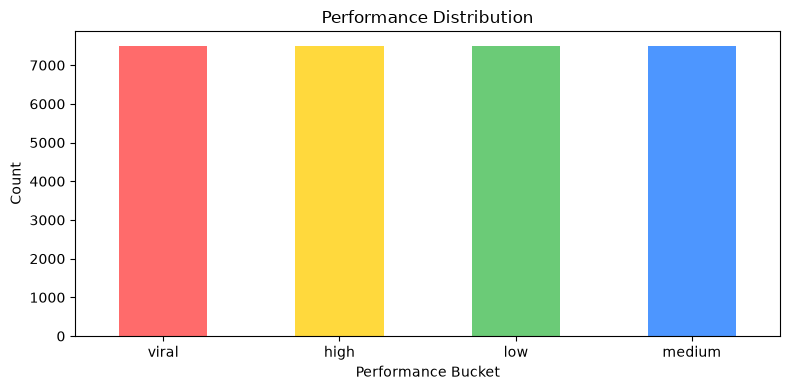

In [5]:
print("=== PERFORMANCE BUCKET DISTRIBUTION ===")
print(insta_df['performance_bucket_label'].value_counts())

# Plot it
plt.figure(figsize=(8,4))
insta_df['performance_bucket_label'].value_counts().plot(kind='bar', color=['#ff6b6b','#ffd93d','#6bcb77','#4d96ff'])
plt.title('Performance Distribution')
plt.xlabel('Performance Bucket')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
print("=== ACCOUNT TYPES ===")
print(insta_df['account_type'].value_counts())

print("\n=== MEDIA TYPES ===")
print(insta_df['media_type'].value_counts())

print("\n=== CONTENT CATEGORIES ===")
print(insta_df['content_category'].value_counts())

print("\n=== TRAFFIC SOURCES ===")
print(insta_df['traffic_source'].value_counts())

print("\n=== DAY OF WEEK ===")
print(insta_df['day_of_week'].value_counts())

=== ACCOUNT TYPES ===
account_type
creator    20944
brand       9055
Name: count, dtype: int64

=== MEDIA TYPES ===
media_type
image       11927
carousel    10627
reel         7445
Name: count, dtype: int64

=== CONTENT CATEGORIES ===
content_category
Photography    3035
Fashion        3034
Technology     3025
Lifestyle      3017
Food           3010
Fitness        3004
Music          3003
Travel         2968
Beauty         2953
Comedy         2950
Name: count, dtype: int64

=== TRAFFIC SOURCES ===
traffic_source
Home Feed     5069
Hashtags      5063
Reels Feed    5026
External      5005
Profile       4962
Explore       4874
Name: count, dtype: int64

=== DAY OF WEEK ===
day_of_week
Thursday     4351
Tuesday      4351
Wednesday    4341
Monday       4279
Saturday     4254
Friday       4218
Sunday       4205
Name: count, dtype: int64


In [7]:
print("=== KEY STATS ===")
insta_df[['follower_count','likes','comments','shares','saves',
          'reach','engagement_rate','hashtags_count','caption_length']].describe().round(2)

=== KEY STATS ===


,follower_count,likes,comments,shares,saves,reach,engagement_rate,hashtags_count,caption_length
count,29999.00,29999.00,29999.00,29999.00,29999.00,29999.00,29999.00,29999.00,29999.00
mean,10278.31,287.65,8.52,14.43,42.52,6272.48,0.04,7.99,120.08
std,6691.86,317.65,10.12,16.42,47.81,4985.88,0.02,2.83,11.01
min,3083.00,0.00,0.00,0.00,0.00,268.00,0.00,0.00,70.00
25%,5824.00,104.00,3.00,5.00,15.00,3058.00,0.02,6.00,113.00
50%,9044.00,199.00,6.00,10.00,29.00,4913.00,0.04,8.00,120.00
75%,10739.00,363.00,11.00,19.00,54.00,7863.00,0.06,10.00,127.00
max,31095.00,10632.00,339.00,516.00,1542.00,73339.00,0.27,21.00,166.00


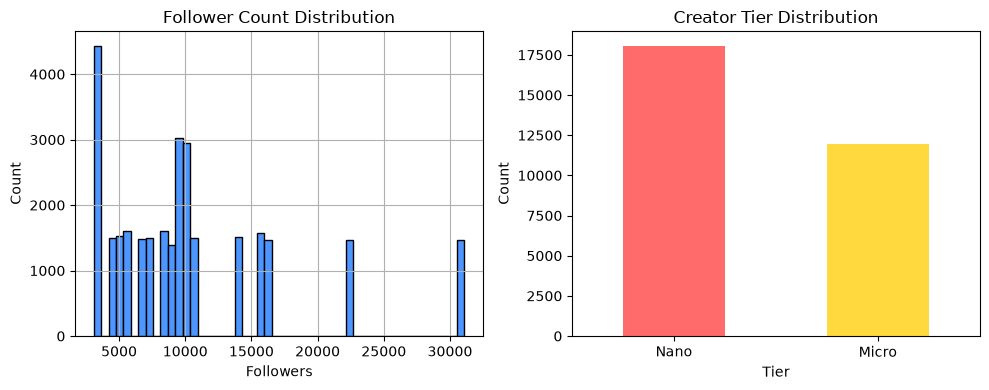

creator_tier
Nano     18060
Micro    11939
Name: count, dtype: int64


In [8]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
insta_df['follower_count'].hist(bins=50, color='#4d96ff', edgecolor='black')
plt.title('Follower Count Distribution')
plt.xlabel('Followers')
plt.ylabel('Count')

plt.subplot(1,2,2)
# Assign creator tiers
def assign_tier(followers):
    if followers < 10000:
        return 'Nano'
    elif followers < 100000:
        return 'Micro'
    elif followers < 500000:
        return 'Mid'
    elif followers < 1000000:
        return 'Macro'
    else:
        return 'Mega'

insta_df['creator_tier'] = insta_df['follower_count'].apply(assign_tier)
insta_df['creator_tier'].value_counts().plot(kind='bar', color=['#ff6b6b','#ffd93d','#6bcb77','#4d96ff','#c77dff'])
plt.title('Creator Tier Distribution')
plt.xlabel('Tier')
plt.ylabel('Count')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

print(insta_df['creator_tier'].value_counts())

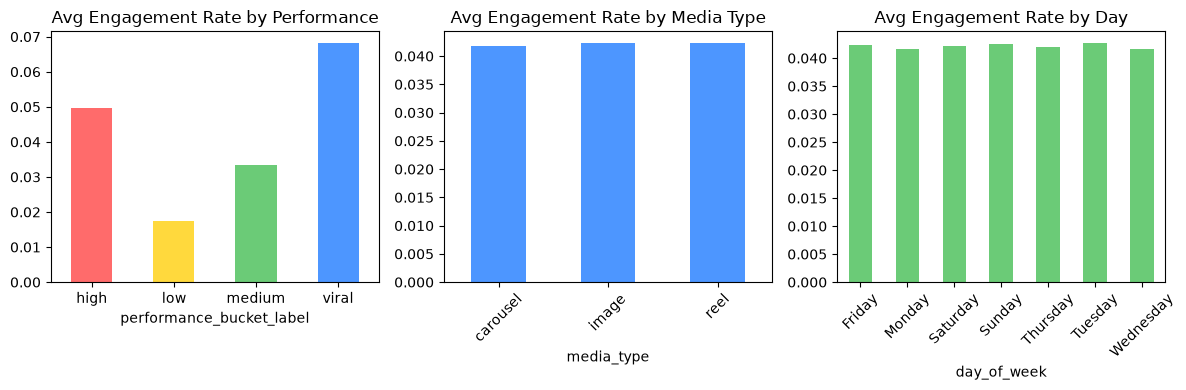

In [9]:
# Engagement rate by performance bucket
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
insta_df.groupby('performance_bucket_label')['engagement_rate'].mean().plot(
    kind='bar', color=['#ff6b6b','#ffd93d','#6bcb77','#4d96ff'])
plt.title('Avg Engagement Rate by Performance')
plt.xticks(rotation=0)

plt.subplot(1,3,2)
insta_df.groupby('media_type')['engagement_rate'].mean().plot(
    kind='bar', color='#4d96ff')
plt.title('Avg Engagement Rate by Media Type')
plt.xticks(rotation=45)

plt.subplot(1,3,3)
insta_df.groupby('day_of_week')['engagement_rate'].mean().plot(
    kind='bar', color='#6bcb77')
plt.title('Avg Engagement Rate by Day')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [6]:
import pandas as pd
pro=pd.read_csv('../data/processed_data.csv')
pro.head(3)
pro.columns

Index(['post_id', 'account_id', 'account_type', 'follower_count', 'media_type',
       'content_category', 'traffic_source', 'has_call_to_action',
       'post_datetime', 'post_date', 'post_hour', 'day_of_week', 'likes',
       'comments', 'shares', 'saves', 'reach', 'impressions',
       'engagement_rate', 'followers_gained', 'caption_length',
       'hashtags_count', 'performance_bucket_label', 'creator_tier',
       'engagement_bucket', 'is_weekend', 'caption_bucket', 'hashtag_bucket',
       'save_ratio', 'share_ratio', 'hour_bucket'],
      dtype='str')

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load datasets
df = pd.read_csv('../data/social_media_engagement_dataset.csv')

In [9]:
df.shape
df.columns
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Post_ID          5000 non-null   str    
 1   Timestamp        5000 non-null   str    
 2   Platform         5000 non-null   str    
 3   Content_Type     5000 non-null   str    
 4   Category         5000 non-null   str    
 5   Likes            5000 non-null   int64  
 6   Comments         5000 non-null   int64  
 7   Shares           5000 non-null   int64  
 8   Views            5000 non-null   int64  
 9   Saves            5000 non-null   int64  
 10  Follower_Count   5000 non-null   int64  
 11  Engagement_Rate  5000 non-null   float64
 12  Hour_of_Day      5000 non-null   int64  
 13  Day_of_Week      5000 non-null   str    
 14  Hashtag_Count    5000 non-null   int64  
 15  Content_Length   5000 non-null   int64  
 16  Sentiment        5000 non-null   str    
 17  Influencer_Tier  5000 non

,Likes,Comments,Shares,Views,Saves,Follower_Count,Engagement_Rate,Hour_of_Day,Hashtag_Count,Content_Length
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,7536.838400,339.898800,835.233400,110968.397000,753.150600,249959.204000,11.960148,11.562600,14.755800,754.508400
std,10169.129568,399.813585,1013.769853,181287.350216,932.653475,144592.908235,71.462053,6.946577,8.666117,576.334039
min,18.000000,1.000000,2.000000,527.000000,5.000000,543.000000,0.050000,0.000000,0.000000,15.000000
25%,1707.750000,96.000000,177.000000,18506.750000,200.000000,124560.250000,1.030000,5.000000,7.000000,280.000000
50%,4073.500000,212.000000,427.500000,40663.500000,424.000000,248930.500000,2.300000,12.000000,15.000000,549.000000
75%,7783.000000,377.000000,1111.500000,84226.750000,805.000000,374697.500000,6.245000,18.000000,22.000000,1226.250000
max,49949.000000,1999.000000,4997.000000,999256.000000,4985.000000,499815.000000,3510.460000,23.000000,29.000000,1999.000000


In [10]:
df.isnull().sum()

Post_ID            0
Timestamp          0
Platform           0
Content_Type       0
Category           0
Likes              0
Comments           0
Shares             0
Views              0
Saves              0
Follower_Count     0
Engagement_Rate    0
Hour_of_Day        0
Day_of_Week        0
Hashtag_Count      0
Content_Length     0
Sentiment          0
Influencer_Tier    0
Has_Media          0
Is_Verified        0
dtype: int64

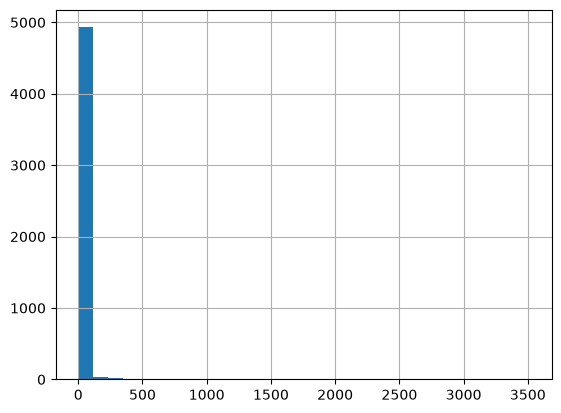

In [12]:
df['Engagement_Rate'].hist(bins=30)
plt.show()

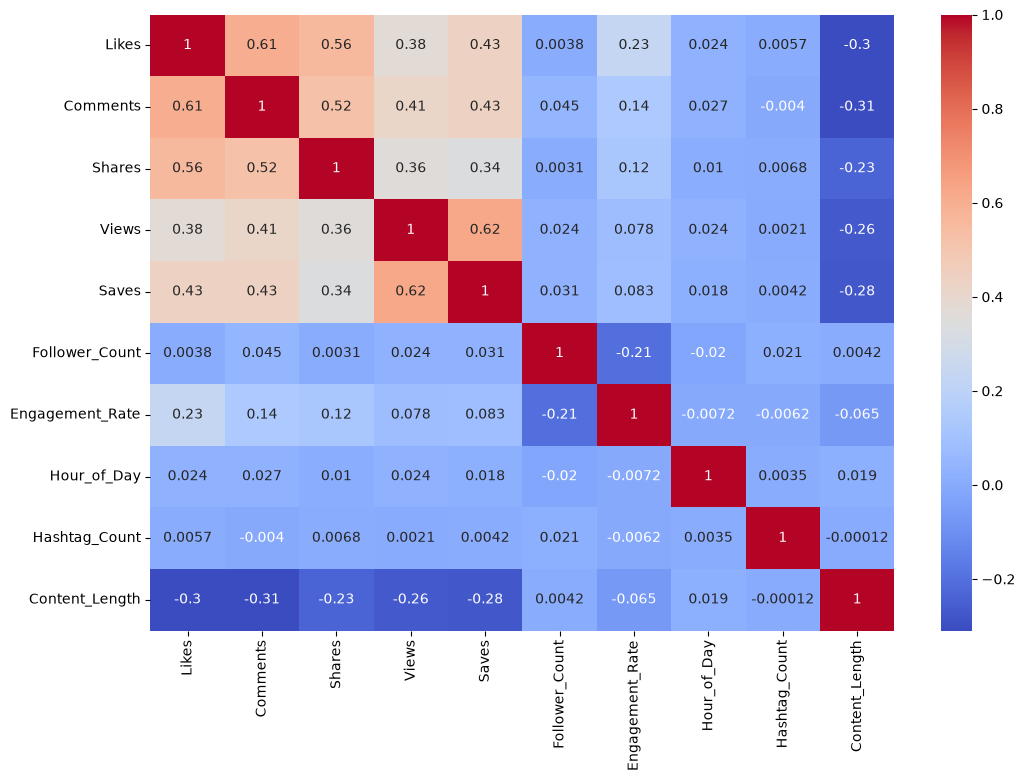

In [13]:
import seaborn as sns

numeric_cols = df.select_dtypes(include=['int64','float64']).columns

plt.figure(figsize=(12,8))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

In [15]:
print(df.groupby('Hour_of_Day')['Engagement_Rate'].mean().sort_values(ascending=False).head(10)) #best posting hours

Hour_of_Day
8     24.620625
20    23.129307
7     21.998700
18    16.256591
0     15.740408
1     15.590870
9     12.807315
16    12.756150
14    11.520406
13    11.515689
Name: Engagement_Rate, dtype: float64


In [16]:
print(df.groupby('Day_of_Week')['Engagement_Rate'].mean().sort_values(ascending=False))

Day_of_Week
Friday       19.118819
Monday       13.115090
Saturday     12.153433
Tuesday      11.410990
Thursday      9.821385
Sunday        9.421870
Wednesday     8.739381
Name: Engagement_Rate, dtype: float64


In [17]:
print(df.groupby('Content_Type')['Engagement_Rate'].mean().sort_values(ascending=False))

Content_Type
Stitch            45.382664
Duet              41.630242
Video             20.407987
Reel              11.674739
Short             10.744628
Community Post    10.188222
Carousel           8.376246
Post               7.708942
Live               7.408827
Tweet              6.304728
Photo              6.283531
Story              5.924190
Thread             4.834110
Retweet            3.745498
Poll               3.282708
Article            1.446638
Document           1.178485
Name: Engagement_Rate, dtype: float64


In [18]:
print(df.groupby('Category')['Engagement_Rate'].mean().sort_values(ascending=False))

Category
Lifestyle        19.127921
Travel           15.206231
Technology       13.960968
Food             12.953535
Business         11.964895
Education        11.890121
Entertainment    11.565625
Fitness          10.378702
Gaming            9.912857
Sports            9.535611
Health            9.323678
Fashion           7.610304
Name: Engagement_Rate, dtype: float64


In [19]:
print(df.groupby('Influencer_Tier')['Engagement_Rate'].mean().sort_values(ascending=False))

Influencer_Tier
Nano        242.022990
Micro        39.548431
Mid-tier     11.714161
Macro         3.450887
Name: Engagement_Rate, dtype: float64


In [20]:
print(df['Sentiment'].value_counts())

print(df['Content_Type'].value_counts())

print(df['Influencer_Tier'].value_counts())

Sentiment
Positive    2503
Neutral     1747
Negative     750
Name: count, dtype: int64
Content_Type
Video             616
Story             568
Poll              384
Post              378
Live              358
Carousel          333
Photo             320
Reel              306
Stitch            259
Retweet           251
Duet              248
Tweet             239
Thread            236
Community Post    135
Document          132
Short             121
Article           116
Name: count, dtype: int64
Influencer_Tier
Macro       3993
Mid-tier     483
Micro        427
Nano          97
Name: count, dtype: int64


In [21]:
print(df['Engagement_Rate'].describe())

count    5000.000000
mean       11.960148
std        71.462053
min         0.050000
25%         1.030000
50%         2.300000
75%         6.245000
max      3510.460000
Name: Engagement_Rate, dtype: float64


In [22]:
df = df[df['Engagement_Rate'] <= df['Engagement_Rate'].quantile(0.99)]

In [ ]:
import pandas as pd

df = pd.read_csv("../data/processed_prepost.csv")

print(df["Engagement_Rate"].describe())

28
count    5000.000000
mean       11.960148
std        71.462053
min         0.050000
25%         1.030000
50%         2.300000
75%         6.245000
max      3510.460000
Name: Engagement_Rate, dtype: float64


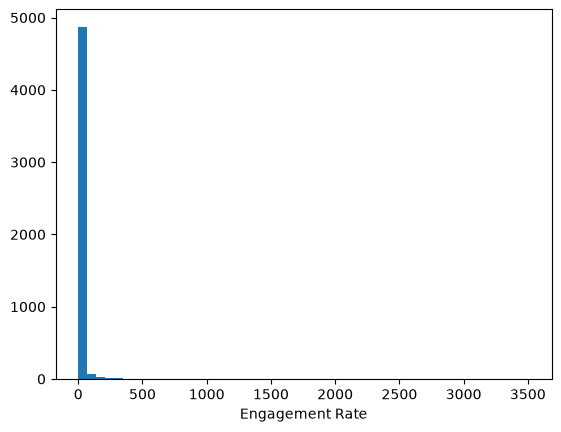

In [ ]:
plt.hist(df["Engagement_Rate"], bins=50)
plt.show()



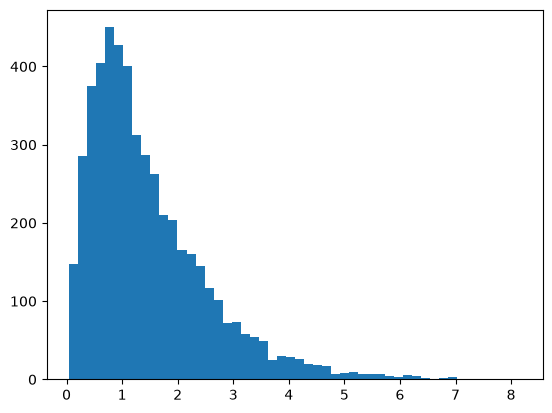

In [35]:
import numpy as np

plt.hist(np.log1p(df["Engagement_Rate"]), bins=50)
plt.show()

In [36]:
print(df["Engagement_Rate"].quantile([0.90,0.95,0.99,0.995,0.999]))

0.900     17.20800
0.950     34.59600
0.990    167.99900
0.995    316.48775
0.999    939.34833
Name: Engagement_Rate, dtype: float64


In [37]:
print(df.groupby("Platform")["Engagement_Rate"].mean())
print(df.groupby("Content_Type")["Engagement_Rate"].mean())

Platform
Facebook      7.168465
Instagram     8.124170
LinkedIn      1.750876
TikTok       41.827111
Twitter       4.757656
YouTube      10.460668
Name: Engagement_Rate, dtype: float64
Content_Type
Article            1.446638
Carousel           8.376246
Community Post    10.188222
Document           1.178485
Duet              41.630242
Live               7.408827
Photo              6.283531
Poll               3.282708
Post               7.708942
Reel              11.674739
Retweet            3.745498
Short             10.744628
Stitch            45.382664
Story              5.924190
Thread             4.834110
Tweet              6.304728
Video             20.407987
Name: Engagement_Rate, dtype: float64


In [38]:
import pandas as pd
df = pd.read_csv("../data/processed_prepost.csv")
print(df['Engagement_Rate'].sort_values(ascending=False).head(20))
print("\n% of rows with engagement rate > 100:", (df['Engagement_Rate'] > 100).mean() * 100)

4615    3510.46
3918    1334.84
4129    1092.18
1846    1078.64
4243     987.63
3948     939.30
4807     816.25
1693     720.98
4394     618.08
4123     606.44
2728     580.22
4139     579.48
128      577.32
1624     511.34
55       476.41
4217     443.11
3226     441.42
257      428.64
3573     426.71
1141     413.27
Name: Engagement_Rate, dtype: float64

% of rows with engagement rate > 100: 1.7399999999999998


In [1]:
print(df.groupby('Platform')['Engagement_Rate'].describe())

NameError: name 'df' is not defined

NameError: name '__file__' is not defined